# 01 Revisión práctica de Machine Learning — solución completa

Este cuaderno resuelve `01_revml.ipynb` con **Iris** y **Diabetes** de scikit-learn. Las predicciones iniciales son hipótesis razonadas de esta solución, escritas antes de ejecutar los experimentos; conviene que el estudiante las compare con sus propias expectativas.

**Protocolo común:** semilla 42; 60 % entrenamiento, 20 % validación y 20 % prueba. En clasificación se estratifica por clase. Los hiperparámetros se eligen con validación; prueba se consulta una sola vez después de fijarlos. Cada transformación aprendida (escaladores de variables y, para el MLP de regresión, del objetivo) se ajusta exclusivamente con los datos de entrenamiento del modelo. No se reajustan modelos a partir de sus resultados de prueba.

**Reproducción:** Python 3.13, scikit-learn, NumPy, pandas, Matplotlib, IPython y Jupyter. Ejecutar las celdas en orden.

### Cinco tipos de problemas de Machine Learning

| Tipo | Entrada y salida esperada | Ejemplo |
|---|---|---|
| Clasificación | Datos con etiquetas categóricas → clase | Especie de Iris |
| Regresión | Datos con valores numéricos objetivo → número | Progresión de Diabetes |
| Clustering | Datos sin etiquetas objetivo → grupos por similitud | Agrupar flores por sus medidas |
| Recomendación | Usuarios, elementos e interacciones → elementos de interés | Sugerir artículos a un lector |
| Asociación | Transacciones o conjuntos → reglas de coocurrencia | Productos que aparecen juntos |

En este cuaderno se implementan clasificación y regresión porque son los dos experimentos pedidos. La estandarización cambia la escala de entrada y, con ella, distancias, productos internos y gradientes usados por varios modelos; se ajusta dentro del entrenamiento para evitar que validación o prueba influyan en esa transformación. Los árboles dividen por umbrales y suelen cambiar poco ante un reescalamiento lineal de cada variable.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.datasets import load_iris, load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge, Lasso
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.exceptions import ConvergenceWarning
import sklearn

warnings.filterwarnings('ignore', category=ConvergenceWarning)
SEED = 42
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 140)
print(f'scikit-learn {sklearn.__version__}; semilla {SEED}')

scikit-learn 1.8.0; semilla 42


## 1. Datos y protocolo experimental — Iris

Cada fila representa una flor de Iris. Las cuatro variables son medidas en centímetros: largo y ancho del sépalo, largo y ancho del pétalo. La etiqueta indica una de tres especies: *setosa*, *versicolor* o *virginica*. La siguiente celda comprueba dimensiones, cantidades, muestra y distribución directamente a partir de los datos.

,Concepto,Valor
0,Instancias,150
1,Características,4
2,Forma de X,"(150, 4)"
3,Forma de y,"(150,)"
4,Clases,"setosa, versicolor, virginica"


,Característica,Significado,Unidad
0,sepal length (cm),largo del sépalo,cm
1,sepal width (cm),ancho del sépalo,cm
2,petal length (cm),largo del pétalo,cm
3,petal width (cm),ancho del pétalo,cm


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),clase
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


,Ejemplos
Clase,
setosa,50
versicolor,50
virginica,50


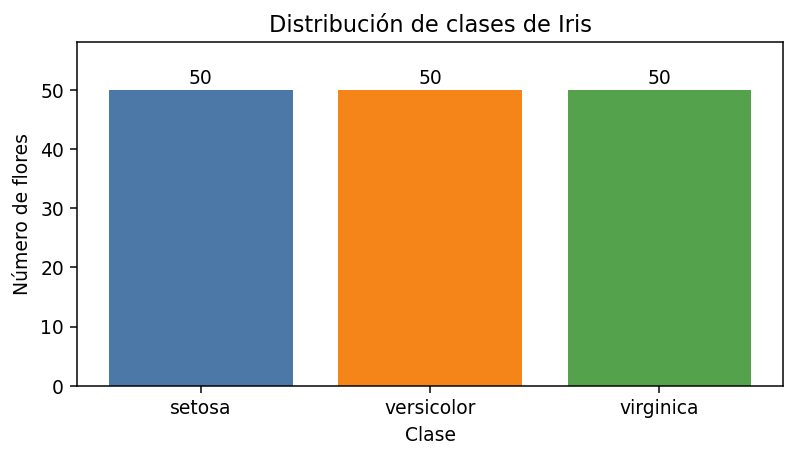

In [2]:
iris = load_iris(as_frame=True)
X_iris = iris.data.copy()
y_iris = iris.target.copy()
iris_names = list(iris.target_names)
iris_counts = y_iris.map(dict(enumerate(iris_names))).value_counts().reindex(iris_names)
display(pd.DataFrame({
    'Concepto': ['Instancias', 'Características', 'Forma de X', 'Forma de y', 'Clases'],
    'Valor': [len(X_iris), X_iris.shape[1], str(X_iris.shape), str(y_iris.shape), ', '.join(iris_names)]
}))
display(pd.DataFrame({
    'Característica': X_iris.columns,
    'Significado': ['largo del sépalo', 'ancho del sépalo', 'largo del pétalo', 'ancho del pétalo'],
    'Unidad': ['cm'] * 4
}))
display(X_iris.assign(clase=y_iris.map(dict(enumerate(iris_names)))).head(5))
display(iris_counts.rename_axis('Clase').to_frame('Ejemplos'))
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(iris_counts.index, iris_counts.values, color=['#4C78A8', '#F58518', '#54A24B'])
ax.set(title='Distribución de clases de Iris', xlabel='Clase', ylabel='Número de flores', ylim=(0, 58))
for i, count in enumerate(iris_counts.values):
    ax.text(i, count + 1, str(count), ha='center')
plt.tight_layout()
plt.show()

### Predicciones iniciales de clasificación (antes del entrenamiento)

1. **Sensibilidad a la escala:** regresión logística, SVM y MLP probablemente cambiarán al modificar la escala; Gaussian Naive Bayes también estima distribuciones por variable, aunque un cambio lineal de unidades suele alterar poco su clasificación. Los árboles y sus ensambles son mucho menos sensibles a ese cambio. Se estandarizarán **todos** los clasificadores para cumplir la consigna y mantener la misma entrada.
2. **Fronteras más simples:** la regresión logística y el SVM lineal producen fronteras lineales; un árbol muy poco profundo también es simple, pero crea cortes por eje. No hay una única noción de simplicidad entre familias.
3. **Mejor modelo incierto:** la separación real de las clases, la muestra finita y los hiperparámetros determinan el resultado. Validación permite comparar sin usar prueba para elegir.

In [3]:
Xi_train, Xi_temp, yi_train, yi_temp = train_test_split(
    X_iris, y_iris, test_size=0.40, stratify=y_iris, random_state=SEED
)
Xi_val, Xi_test, yi_val, yi_test = train_test_split(
    Xi_temp, yi_temp, test_size=0.50, stratify=yi_temp, random_state=SEED
)
display(pd.DataFrame({
    'Partición': ['Entrenamiento', 'Validación', 'Prueba'],
    'Instancias': [len(Xi_train), len(Xi_val), len(Xi_test)],
    **{name: [int((y == k).sum()) for y in (yi_train, yi_val, yi_test)]
       for k, name in enumerate(iris_names)}
}))
assert not (set(Xi_train.index) & set(Xi_val.index))
assert not (set(Xi_train.index) & set(Xi_test.index))
assert not (set(Xi_val.index) & set(Xi_test.index))

,Partición,Instancias,setosa,versicolor,virginica
0,Entrenamiento,90,30,30,30
1,Validación,30,10,10,10
2,Prueba,30,10,10,10


### Configuraciones y selección por validación

La primera opción de cada lista es la configuración inicial. Las siguientes son ajustes limitados. Se escoge la mayor F1 macro de validación; en empate, mayor accuracy y luego la primera configuración listada. El escalador está dentro de cada pipeline y se ajusta solo con entrenamiento.

In [4]:
class_candidates = {
    'Gaussian Naive Bayes': [
        ('inicial', GaussianNB(var_smoothing=1e-9)),
        ('ajuste', GaussianNB(var_smoothing=1e-6))],
    'Regresión logística': [
        ('inicial', LogisticRegression(C=1, max_iter=1000, random_state=SEED)),
        ('ajuste C=0.1', LogisticRegression(C=0.1, max_iter=1000, random_state=SEED)),
        ('ajuste C=10', LogisticRegression(C=10, max_iter=1000, random_state=SEED))],
    'SVM lineal': [
        ('inicial', SVC(kernel='linear', C=1, random_state=SEED)),
        ('ajuste C=0.1', SVC(kernel='linear', C=0.1, random_state=SEED)),
        ('ajuste C=10', SVC(kernel='linear', C=10, random_state=SEED))],
    'Árbol de decisión': [
        ('inicial', DecisionTreeClassifier(max_depth=3, random_state=SEED)),
        ('ajuste profundidad=2', DecisionTreeClassifier(max_depth=2, random_state=SEED)),
        ('ajuste profundidad=4', DecisionTreeClassifier(max_depth=4, random_state=SEED))],
    'Random Forest': [
        ('inicial', RandomForestClassifier(n_estimators=100, max_depth=None, random_state=SEED)),
        ('ajuste profundidad=3', RandomForestClassifier(n_estimators=100, max_depth=3, random_state=SEED))],
    'Gradient Boosting': [
        ('inicial', GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=SEED)),
        ('ajuste tasa=0.05', GradientBoostingClassifier(n_estimators=100, learning_rate=0.05, random_state=SEED))],
    'MLP': [
        ('inicial', MLPClassifier(hidden_layer_sizes=(16,), alpha=0.01, solver='lbfgs', max_iter=1000, random_state=SEED)),
        ('ajuste 8 neuronas', MLPClassifier(hidden_layer_sizes=(8,), alpha=0.01, solver='lbfgs', max_iter=1000, random_state=SEED)),
        ('ajuste alpha=0.1', MLPClassifier(hidden_layer_sizes=(16,), alpha=0.1, solver='lbfgs', max_iter=1000, random_state=SEED))]
}
class_val_rows = []
class_models = {}
class_config = {}
for model_name, candidates in class_candidates.items():
    outcomes = []
    for order, (stage, estimator) in enumerate(candidates):
        model = Pipeline([('escalador', StandardScaler()), ('modelo', estimator)])
        model.fit(Xi_train, yi_train)
        prediction = model.predict(Xi_val)
        acc = accuracy_score(yi_val, prediction)
        f1 = f1_score(yi_val, prediction, average='macro', zero_division=0)
        params = {k: v for k, v in estimator.get_params().items()
                  if k in ('var_smoothing', 'C', 'kernel', 'max_depth', 'n_estimators',
                           'learning_rate', 'hidden_layer_sizes', 'alpha', 'solver')}
        class_val_rows.append({'Modelo': model_name, 'Opción': stage, 'Hiperparámetros': str(params),
                               'Accuracy validación': acc, 'F1 macro validación': f1})
        outcomes.append((f1, acc, -order, model, params, stage))
    best = max(outcomes, key=lambda t: t[:3])
    class_models[model_name] = best[3]
    class_config[model_name] = {'Parámetros': best[4], 'Opción': best[5]}
class_val = pd.DataFrame(class_val_rows)
display(class_val.style.format({'Accuracy validación': '{:.3f}', 'F1 macro validación': '{:.3f}'}))
display(pd.DataFrame([{'Modelo': name, 'Opción fijada': c['Opción'],
                       'Hiperparámetros': str(c['Parámetros'])}
                      for name, c in class_config.items()]))

,Modelo,Opción,Hiperparámetros,Accuracy validación,F1 macro validación
0,Gaussian Naive Bayes,inicial,{'var_smoothing': 1e-09},0.933,0.933
1,Gaussian Naive Bayes,ajuste,{'var_smoothing': 1e-06},0.933,0.933
2,Regresión logística,inicial,"{'C': 1, 'solver': 'lbfgs'}",0.933,0.933
3,Regresión logística,ajuste C=0.1,"{'C': 0.1, 'solver': 'lbfgs'}",0.867,0.865
4,Regresión logística,ajuste C=10,"{'C': 10, 'solver': 'lbfgs'}",0.933,0.933
5,SVM lineal,inicial,"{'C': 1, 'kernel': 'linear'}",0.967,0.967
6,SVM lineal,ajuste C=0.1,"{'C': 0.1, 'kernel': 'linear'}",0.933,0.933
7,SVM lineal,ajuste C=10,"{'C': 10, 'kernel': 'linear'}",0.933,0.933
8,Árbol de decisión,inicial,{'max_depth': 3},0.967,0.967
9,Árbol de decisión,ajuste profundidad=2,{'max_depth': 2},0.900,0.900


,Modelo,Opción fijada,Hiperparámetros
0,Gaussian Naive Bayes,inicial,{'var_smoothing': 1e-09}
1,Regresión logística,inicial,"{'C': 1, 'solver': 'lbfgs'}"
2,SVM lineal,inicial,"{'C': 1, 'kernel': 'linear'}"
3,Árbol de decisión,inicial,{'max_depth': 3}
4,Random Forest,inicial,"{'max_depth': None, 'n_estimators': 100}"
5,Gradient Boosting,inicial,"{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100}"
6,MLP,inicial,"{'alpha': 0.01, 'hidden_layer_sizes': (16,), 'learning_rate': 'constant', 'solver': 'lbfgs'}"


### Evaluación final en prueba

Las siete configuraciones anteriores quedan fijadas. La siguiente celda calcula la tabla pedida y las tres matrices de confusión. No se vuelve a seleccionar un modelo después de mirar esta partición.

,Modelo,Transformación,Hiperparámetros principales,Accuracy de prueba,F1 macro de prueba
0,Árbol de decisión,StandardScaler (pipeline),{'max_depth': 3},1.000,1.000
1,Gaussian Naive Bayes,StandardScaler (pipeline),{'var_smoothing': 1e-09},0.933,0.933
2,Regresión logística,StandardScaler (pipeline),"{'C': 1, 'solver': 'lbfgs'}",0.933,0.933
3,SVM lineal,StandardScaler (pipeline),"{'C': 1, 'kernel': 'linear'}",0.933,0.933
4,Gradient Boosting,StandardScaler (pipeline),"{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100}",0.933,0.933
5,Random Forest,StandardScaler (pipeline),"{'max_depth': None, 'n_estimators': 100}",0.900,0.898
6,MLP,StandardScaler (pipeline),"{'alpha': 0.01, 'hidden_layer_sizes': (16,), 'learning_rate': 'constant', 'solver': 'lbfgs'}",0.900,0.898


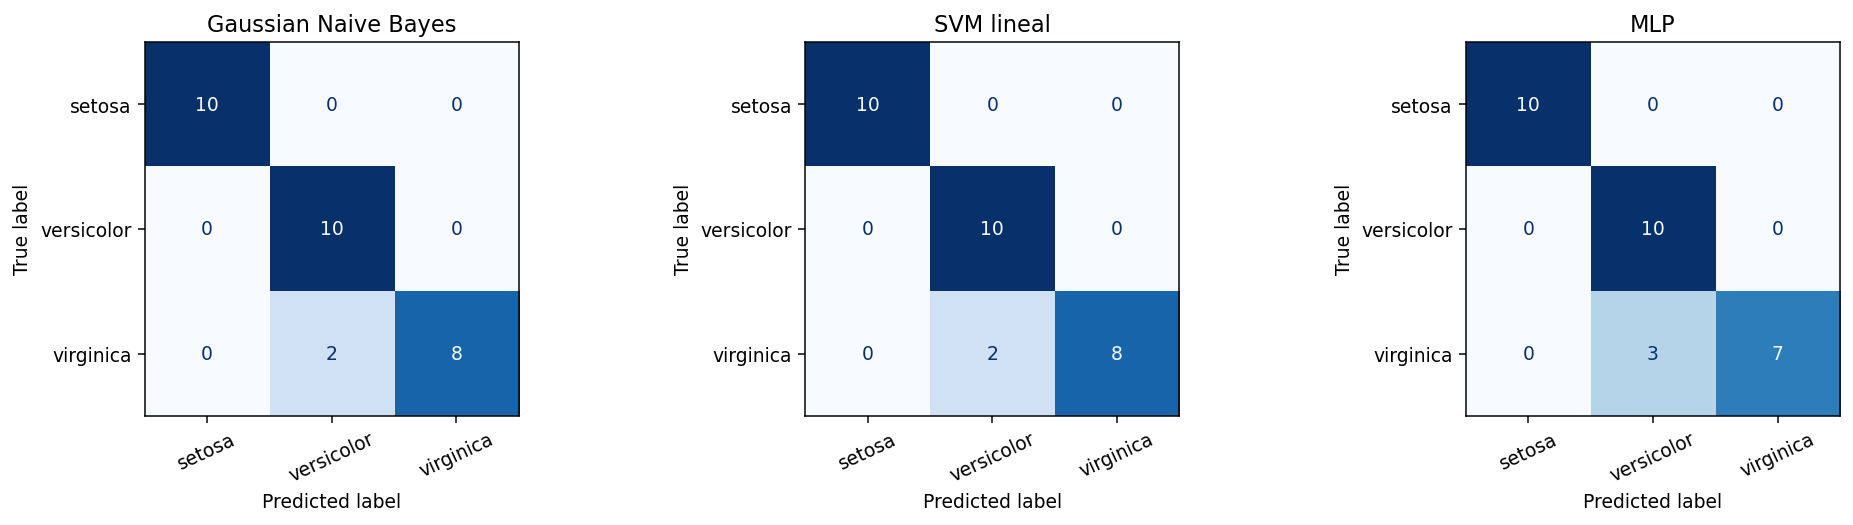

In [5]:
class_predictions = {name: model.predict(Xi_test) for name, model in class_models.items()}
class_test = pd.DataFrame([
    {'Modelo': name, 'Transformación': 'StandardScaler (pipeline)',
     'Hiperparámetros principales': str(class_config[name]['Parámetros']),
     'Accuracy de prueba': accuracy_score(yi_test, pred),
     'F1 macro de prueba': f1_score(yi_test, pred, average='macro', zero_division=0)}
    for name, pred in class_predictions.items()
]).sort_values(['F1 macro de prueba', 'Accuracy de prueba'], ascending=False, kind='stable').reset_index(drop=True)
display(class_test.style.format({'Accuracy de prueba': '{:.3f}', 'F1 macro de prueba': '{:.3f}'}))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, name in zip(axes, ['Gaussian Naive Bayes', 'SVM lineal', 'MLP']):
    cm = confusion_matrix(yi_test, class_predictions[name], labels=[0, 1, 2])
    ConfusionMatrixDisplay(cm, display_labels=iris_names).plot(ax=ax, colorbar=False, cmap='Blues', values_format='d')
    ax.set_title(name)
    ax.tick_params(axis='x', labelrotation=25)
plt.tight_layout()
plt.show()

In [6]:
best_class = class_test.iloc[0]
same_story = class_test.sort_values('Accuracy de prueba', ascending=False, kind='stable').iloc[0]['Modelo'] == best_class['Modelo']
display(Markdown(f'''### Interpretación de la clasificación

1. **Mejor desempeño observado:** {best_class['Modelo']} tiene la mayor F1 macro de prueba ({best_class['F1 macro de prueba']:.3f}); su accuracy es {best_class['Accuracy de prueba']:.3f}. Con solo {len(yi_test)} flores de prueba, diferencias pequeñas no prueban superioridad general.
2. **Más sencillo de programar:** Gaussian Naive Bayes requiere pocas decisiones de configuración y una sola llamada a `fit`/`predict`; la facilidad de uso de la API es en parte subjetiva.
3. **Accuracy frente a F1 macro:** {'ambas señalan al mismo primer modelo en esta prueba' if same_story else 'el primer modelo cambia según la métrica en esta prueba'}. Accuracy cuenta aciertos globales; F1 macro promedia la F1 de las tres clases y hace visibles diferencias entre ellas. Conviene mirar también las matrices de confusión.
4. **Macro frente a micro:** macro calcula la métrica por clase y promedia sin ponderar; micro reúne TP, FP y FN de todas las clases antes de calcularla. En clasificación multiclase de etiqueta única, F1 micro coincide con accuracy.
5. **Qué aporta el MLP:** puede aprender relaciones no lineales entre medidas mediante capas ocultas. Esa flexibilidad puede ayudar o sobreajustar; su resultado aquí debe juzgarse por validación y prueba, no por capacidad teórica.

**Softmax y salidas del MLP.** `predict_proba` entrega probabilidades por clase que suman 1; en la salida multiclase, softmax transforma puntuaciones en esas probabilidades relativas. Una probabilidad alta indica confianza del modelo, no certeza ni causalidad. La clase predicha es la de mayor probabilidad.
'''))
display(pd.DataFrame(class_models['MLP'].predict_proba(Xi_test.iloc[:3]),
                     columns=iris_names, index=Xi_test.index[:3]).round(3))

### Interpretación de la clasificación

1. **Mejor desempeño observado:** Árbol de decisión tiene la mayor F1 macro de prueba (1.000); su accuracy es 1.000. Con solo 30 flores de prueba, diferencias pequeñas no prueban superioridad general.
2. **Más sencillo de programar:** Gaussian Naive Bayes requiere pocas decisiones de configuración y una sola llamada a `fit`/`predict`; la facilidad de uso de la API es en parte subjetiva.
3. **Accuracy frente a F1 macro:** ambas señalan al mismo primer modelo en esta prueba. Accuracy cuenta aciertos globales; F1 macro promedia la F1 de las tres clases y hace visibles diferencias entre ellas. Conviene mirar también las matrices de confusión.
4. **Macro frente a micro:** macro calcula la métrica por clase y promedia sin ponderar; micro reúne TP, FP y FN de todas las clases antes de calcularla. En clasificación multiclase de etiqueta única, F1 micro coincide con accuracy.
5. **Qué aporta el MLP:** puede aprender relaciones no lineales entre medidas mediante capas ocultas. Esa flexibilidad puede ayudar o sobreajustar; su resultado aquí debe juzgarse por validación y prueba, no por capacidad teórica.

**Softmax y salidas del MLP.** `predict_proba` entrega probabilidades por clase que suman 1; en la salida multiclase, softmax transforma puntuaciones en esas probabilidades relativas. Una probabilidad alta indica confianza del modelo, no certeza ni causalidad. La clase predicha es la de mayor probabilidad.


,setosa,versicolor,virginica
61,0.0,1.0,0.0
35,1.0,0.0,0.0
56,0.0,1.0,0.0


In [7]:
error_rows = []
for name in ['Gaussian Naive Bayes', 'SVM lineal', 'MLP', 'Regresión logística',
             'Árbol de decisión', 'Random Forest', 'Gradient Boosting']:
    pred = class_predictions[name]
    for pos in np.flatnonzero(pred != yi_test.to_numpy()):
        idx = Xi_test.index[pos]
        error_rows.append({'Modelo': name, 'Índice original': int(idx),
                           'Clase real': iris_names[int(yi_test.iloc[pos])],
                           'Predicción': iris_names[int(pred[pos])],
                           **Xi_test.loc[idx].to_dict()})
selected_errors = []
for row in error_rows:
    if row['Índice original'] not in {r['Índice original'] for r in selected_errors}:
        selected_errors.append(row)
    if len(selected_errors) == 2:
        break
if len(selected_errors) < 2:
    selected_errors = error_rows[:2]
assert len(selected_errors) >= 2, 'Esta partición no produjo dos errores; elegir otra semilla previamente fijada.'
display(pd.DataFrame(selected_errors).round(2))
petal_medians = Xi_train.assign(clase=yi_train.map(dict(enumerate(iris_names)))).groupby('clase')[
    ['petal length (cm)', 'petal width (cm)']].median().reindex(iris_names)
display(Markdown('**Medianas del pétalo en entrenamiento, como referencia:**'))
display(petal_medians.round(2))
error_summary = '; '.join(
    f"índice {row['Índice original']}: {row['Clase real']} → {row['Predicción']}, "
    f"pétalo {row['petal length (cm)']:.1f} × {row['petal width (cm)']:.1f} cm"
    for row in selected_errors
)
display(Markdown(f'''**Lectura de dos errores:** {error_summary}. La tabla permite comparar esas medidas con las medianas de las clases obtenidas solo en entrenamiento. En particular, un pétalo cercano al rango de otra clase puede dificultar la decisión. **Sí** concluimos que los modelos indicados se equivocaron en esos ejemplos y podemos describir sus medidas. **No** podemos identificar la causa exacta del fallo (solapamiento, ruido, tamaño de entrenamiento o etiqueta incorrecta) a partir de dos filas; tampoco inferimos que la especie real esté mal etiquetada.'''))

,Modelo,Índice original,Clase real,Predicción,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,Gaussian Naive Bayes,134,virginica,versicolor,6.1,2.6,5.6,1.4
1,Gaussian Naive Bayes,133,virginica,versicolor,6.3,2.8,5.1,1.5


**Medianas del pétalo en entrenamiento, como referencia:**

,petal length (cm),petal width (cm)
clase,,
setosa,1.5,0.20
versicolor,4.2,1.30
virginica,5.6,2.05


**Lectura de dos errores:** índice 134: virginica → versicolor, pétalo 5.6 × 1.4 cm; índice 133: virginica → versicolor, pétalo 5.1 × 1.5 cm. La tabla permite comparar esas medidas con las medianas de las clases obtenidas solo en entrenamiento. En particular, un pétalo cercano al rango de otra clase puede dificultar la decisión. **Sí** concluimos que los modelos indicados se equivocaron en esos ejemplos y podemos describir sus medidas. **No** podemos identificar la causa exacta del fallo (solapamiento, ruido, tamaño de entrenamiento o etiqueta incorrecta) a partir de dos filas; tampoco inferimos que la especie real esté mal etiquetada.

## 3. Comparación de modelos de regresión — Diabetes

Cada fila corresponde a una persona. Las diez variables basales son edad, sexo, índice de masa corporal (`bmi`), presión arterial media (`bp`) y seis medidas séricas (`s1`–`s6`). El objetivo es una medida cuantitativa de la progresión de la diabetes un año después. La descripción del dataset indica que las variables suministradas han sido **centradas y escaladas**; por tanto, sus valores no se interpretan directamente en unidades clínicas originales.

### Predicción inicial (antes del entrenamiento)

Un modelo más flexible **no** tiene por qué reducir siempre el error en personas nuevas: puede capturar ruido del entrenamiento, y con una muestra pequeña la varianza puede superar la mejora en ajuste. Se comprobará con validación y después con una prueba independiente.

In [8]:
diabetes = load_diabetes(as_frame=True)
X_dia = diabetes.data.copy()
y_dia = diabetes.target.copy()
display(pd.DataFrame({'Concepto': ['Instancias', 'Variables', 'Forma de X', 'Forma de y', 'Rango del objetivo'],
                      'Valor': [len(X_dia), X_dia.shape[1], str(X_dia.shape), str(y_dia.shape),
                                f'{y_dia.min():.0f} a {y_dia.max():.0f}']}))
display(pd.DataFrame({'Variable': X_dia.columns,
                      'Descripción': ['edad', 'sexo', 'índice de masa corporal', 'presión arterial media',
                                      'colesterol total', 'colesterol LDL', 'colesterol HDL',
                                      'colesterol total / HDL', 'logaritmo de triglicéridos', 'glucosa']}))
description_lines = [line.strip() for line in diabetes.DESCR.splitlines()
                     if 'scaled' in line.lower() or 'progression' in line.lower()]
display(Markdown('**Comprobación en `DESCR`:** ' + ' '.join(description_lines[:4])))
Xd_train, Xd_temp, yd_train, yd_temp = train_test_split(
    X_dia, y_dia, test_size=0.40, random_state=SEED
)
Xd_val, Xd_test, yd_val, yd_test = train_test_split(
    Xd_temp, yd_temp, test_size=0.50, random_state=SEED
)
display(pd.DataFrame({'Partición': ['Entrenamiento', 'Validación', 'Prueba'],
                      'Instancias': [len(Xd_train), len(Xd_val), len(Xd_test)]}))
assert not (set(Xd_train.index) & set(Xd_val.index))
assert not (set(Xd_train.index) & set(Xd_test.index))
assert not (set(Xd_val.index) & set(Xd_test.index))

,Concepto,Valor
0,Instancias,442
1,Variables,10
2,Forma de X,"(442, 10)"
3,Forma de y,"(442,)"
4,Rango del objetivo,25 a 346


,Variable,Descripción
0,age,edad
1,sex,sexo
2,bmi,índice de masa corporal
3,bp,presión arterial media
4,s1,colesterol total
5,s2,colesterol LDL
6,s3,colesterol HDL
7,s4,colesterol total / HDL
8,s5,logaritmo de triglicéridos
9,s6,glucosa


**Comprobación en `DESCR`:** quantitative measure of disease progression one year after baseline. :Target: Column 11 is a quantitative measure of disease progression one year after baseline Note: Each of these 10 feature variables have been mean centered and scaled by the standard deviation times the square root of `n_samples` (i.e. the sum of squares of each column totals 1).

,Partición,Instancias
0,Entrenamiento,265
1,Validación,88
2,Prueba,89


### Modelos y ajustes limitados

La primera opción de cada modelo es inicial; se elige el menor RMSE de validación y, en empate, la primera opción. Para modelos lineales, kNN y MLP, `StandardScaler` se ajusta dentro del pipeline. El MLP usa `TransformedTargetRegressor`: escala `y` solo con entrenamiento y `predict` devuelve valores en la escala original. Por eso **todas** las métricas siguientes están en la escala original del objetivo.

In [9]:
def scaled_regressor(estimator):
    return Pipeline([('escalador', StandardScaler()), ('modelo', estimator)])

def mlp_regressor(hidden, alpha):
    inner = scaled_regressor(MLPRegressor(hidden_layer_sizes=hidden, alpha=alpha,
                                         solver='lbfgs', max_iter=1500, random_state=SEED))
    return TransformedTargetRegressor(regressor=inner, transformer=StandardScaler())

reg_candidates = {
    'Regresión lineal': [('inicial', scaled_regressor(LinearRegression()))],
    'Ridge': [('inicial α=1', scaled_regressor(Ridge(alpha=1.0))),
              ('α=0.1', scaled_regressor(Ridge(alpha=0.1))),
              ('α=10', scaled_regressor(Ridge(alpha=10.0))),
              ('α=100', scaled_regressor(Ridge(alpha=100.0)))],
    'Lasso': [('inicial α=1', scaled_regressor(Lasso(alpha=1.0, max_iter=10000))),
              ('α=0.01', scaled_regressor(Lasso(alpha=0.01, max_iter=10000))),
              ('α=0.1', scaled_regressor(Lasso(alpha=0.1, max_iter=10000))),
              ('α=10', scaled_regressor(Lasso(alpha=10.0, max_iter=10000)))],
    'kNN': [('inicial k=5', scaled_regressor(KNeighborsRegressor(n_neighbors=5))),
            ('k=3', scaled_regressor(KNeighborsRegressor(n_neighbors=3))),
            ('k=9', scaled_regressor(KNeighborsRegressor(n_neighbors=9)))],
    'Árbol de regresión': [('inicial profundidad=3', DecisionTreeRegressor(max_depth=3, random_state=SEED)),
                           ('profundidad=2', DecisionTreeRegressor(max_depth=2, random_state=SEED)),
                           ('profundidad=5', DecisionTreeRegressor(max_depth=5, random_state=SEED))],
    'Random Forest': [('inicial', RandomForestRegressor(n_estimators=150, max_depth=None, random_state=SEED)),
                      ('profundidad=5', RandomForestRegressor(n_estimators=150, max_depth=5, random_state=SEED))],
    'Gradient Boosting': [('inicial', GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=SEED)),
                          ('tasa=0.05', GradientBoostingRegressor(n_estimators=100, learning_rate=0.05, random_state=SEED))],
    'MLP': [('inicial (16,), α=1', mlp_regressor((16,), 1.0)),
            ('(32,), α=1', mlp_regressor((32,), 1.0)),
            ('(16,), α=10', mlp_regressor((16,), 10.0))]
}

reg_val_rows = []
reg_models = {}
reg_config = {}
reg_fits = {}
for name, candidates in reg_candidates.items():
    outcomes = []
    reg_fits[name] = []
    for order, (label, model) in enumerate(candidates):
        model.fit(Xd_train, yd_train)
        pred_train = model.predict(Xd_train)
        pred_val = model.predict(Xd_val)
        train_rmse = np.sqrt(mean_squared_error(yd_train, pred_train))
        val_rmse = np.sqrt(mean_squared_error(yd_val, pred_val))
        row = {'Modelo': name, 'Opción': label, 'RMSE entrenamiento': train_rmse,
               'RMSE validación': val_rmse, 'MAE validación': mean_absolute_error(yd_val, pred_val)}
        reg_val_rows.append(row)
        reg_fits[name].append((label, model, train_rmse, val_rmse))
        outcomes.append((val_rmse, order, model, label))
    best = min(outcomes, key=lambda t: (t[0], t[1]))
    reg_models[name] = best[2]
    reg_config[name] = best[3]
reg_val = pd.DataFrame(reg_val_rows)
display(reg_val.style.format({'RMSE entrenamiento': '{:.2f}', 'RMSE validación': '{:.2f}', 'MAE validación': '{:.2f}'}))
display(pd.DataFrame({'Modelo': list(reg_config), 'Opción fijada': list(reg_config.values())}))

,Modelo,Opción,RMSE entrenamiento,RMSE validación,MAE validación
0,Regresión lineal,inicial,54.28,49.15,38.22
1,Ridge,inicial α=1,54.30,49.20,38.29
2,Ridge,α=0.1,54.29,49.16,38.23
3,Ridge,α=10,54.40,49.37,38.50
4,Ridge,α=100,55.44,50.81,40.50
5,Lasso,inicial α=1,54.47,49.53,38.68
6,Lasso,α=0.01,54.29,49.16,38.23
7,Lasso,α=0.1,54.30,49.20,38.30
8,Lasso,α=10,57.39,53.82,44.05
9,kNN,inicial k=5,52.47,57.71,45.45


,Modelo,Opción fijada
0,Regresión lineal,inicial
1,Ridge,α=0.1
2,Lasso,α=0.01
3,kNN,k=9
4,Árbol de regresión,profundidad=2
5,Random Forest,profundidad=5
6,Gradient Boosting,tasa=0.05
7,MLP,"(16,), α=10"


### Evaluación final en prueba

MAE y RMSE se miden en unidades del objetivo. R² compara el modelo con predecir la media de la partición evaluada. Las configuraciones ya están fijadas por validación.

,Modelo,MAE,RMSE,R²
0,MLP,44.86,55.09,0.475
1,Random Forest,44.98,55.62,0.465
2,Gradient Boosting,45.33,56.20,0.454
3,Regresión lineal,46.72,56.97,0.439
4,Ridge,46.73,56.99,0.439
5,Lasso,46.74,56.99,0.438
6,kNN,47.56,58.28,0.413
7,Árbol de regresión,50.45,63.59,0.301


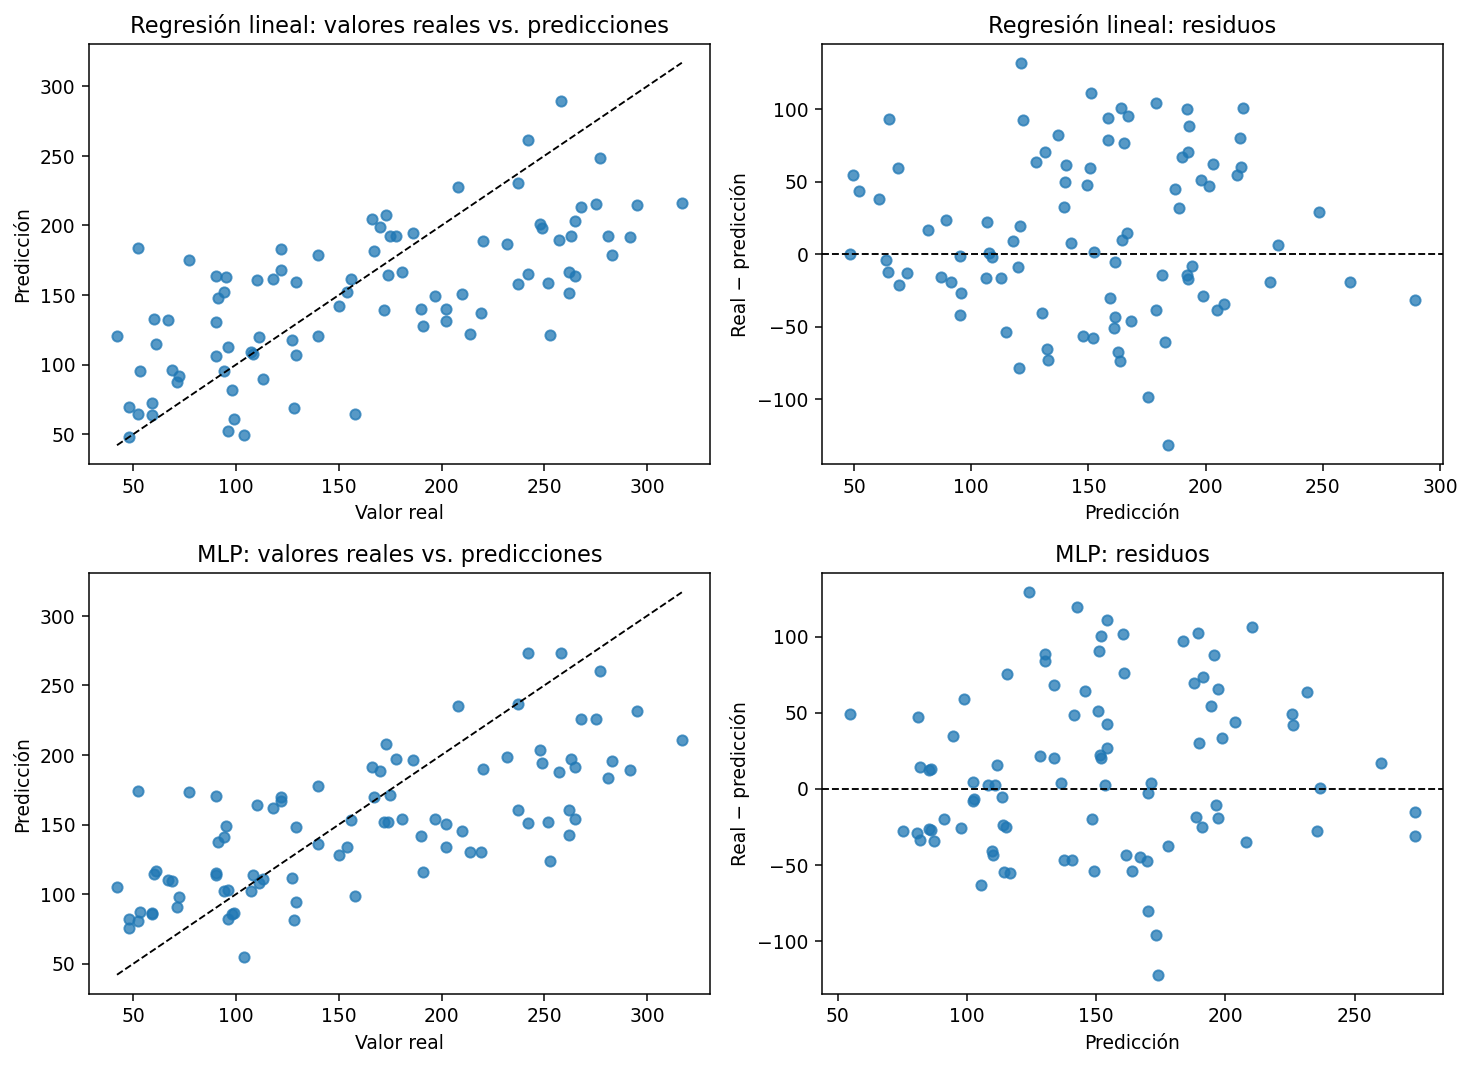

**Dos errores absolutos grandes de Regresión lineal:**

,Valor real,Predicción,Error absoluto,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
304,253.0,121.029,131.971,0.042,0.051,-0.039,0.053,0.077,0.116,-0.040,0.071,-0.023,-0.014
380,52.0,183.811,131.811,0.016,-0.045,0.026,0.059,-0.061,-0.044,-0.014,-0.034,-0.051,-0.026


**Dos errores absolutos grandes de MLP:**

,Valor real,Predicción,Error absoluto,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
304,253.0,123.964,129.036,0.042,0.051,-0.039,0.053,0.077,0.116,-0.040,0.071,-0.023,-0.014
380,52.0,174.136,122.136,0.016,-0.045,0.026,0.059,-0.061,-0.044,-0.014,-0.034,-0.051,-0.026


In [10]:
reg_predictions = {name: model.predict(Xd_test) for name, model in reg_models.items()}
reg_test = pd.DataFrame([
    {'Modelo': name, 'MAE': mean_absolute_error(yd_test, pred),
     'RMSE': np.sqrt(mean_squared_error(yd_test, pred)),
     'R²': r2_score(yd_test, pred)}
    for name, pred in reg_predictions.items()
]).sort_values('RMSE', kind='stable').reset_index(drop=True)
display(reg_test.style.format({'MAE': '{:.2f}', 'RMSE': '{:.2f}', 'R²': '{:.3f}'}))
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for row, name in enumerate(['Regresión lineal', 'MLP']):
    pred = reg_predictions[name]
    residual = yd_test.to_numpy() - pred
    axes[row, 0].scatter(yd_test, pred, alpha=0.75, s=30)
    limits = [min(yd_test.min(), pred.min()), max(yd_test.max(), pred.max())]
    axes[row, 0].plot(limits, limits, 'k--', linewidth=1)
    axes[row, 0].set(title=f'{name}: valores reales vs. predicciones', xlabel='Valor real', ylabel='Predicción')
    axes[row, 1].scatter(pred, residual, alpha=0.75, s=30)
    axes[row, 1].axhline(0, color='black', linestyle='--', linewidth=1)
    axes[row, 1].set(title=f'{name}: residuos', xlabel='Predicción', ylabel='Real − predicción')
plt.tight_layout()
plt.show()
for name in ['Regresión lineal', 'MLP']:
    pred = reg_predictions[name]
    errors = np.abs(yd_test.to_numpy() - pred)
    positions = np.argsort(errors)[-2:][::-1]
    examples = Xd_test.iloc[positions].copy()
    examples.insert(0, 'Valor real', yd_test.iloc[positions].to_numpy())
    examples.insert(1, 'Predicción', pred[positions])
    examples.insert(2, 'Error absoluto', errors[positions])
    display(Markdown(f'**Dos errores absolutos grandes de {name}:**'))
    display(examples.round(3))

### Regularización de Ridge y Lasso

Los coeficientes se comparan en la escala de entrada estandarizada por cada pipeline. Esto permite examinar la penalización, pero la magnitud de un coeficiente no equivale por sí sola a importancia causal. `L1` es la suma de valores absolutos; `L2` es la norma euclídea. Contamos coeficientes exactamente nulos en Lasso con tolerancia numérica de `1e-8`.

,Modelo,α,Norma L1,Norma L2,Máx. |coef.|,Coeficientes nulos,RMSE entrenamiento,RMSE validación
0,Lasso,0.01,139.13,56.56,30.11,0,54.29,49.16
1,Lasso,0.1,123.10,49.26,28.59,0,54.30,49.20
2,Lasso,1,90.59,41.09,28.76,2,54.47,49.53
3,Lasso,10,51.94,30.82,26.20,6,57.39,53.82
4,Ridge,0.1,140.24,56.89,30.48,0,54.29,49.16
5,Ridge,1,126.72,50.57,28.44,0,54.30,49.20
6,Ridge,10,99.82,41.09,27.85,0,54.40,49.37
7,Ridge,1e+02,81.37,31.93,21.48,0,55.44,50.81


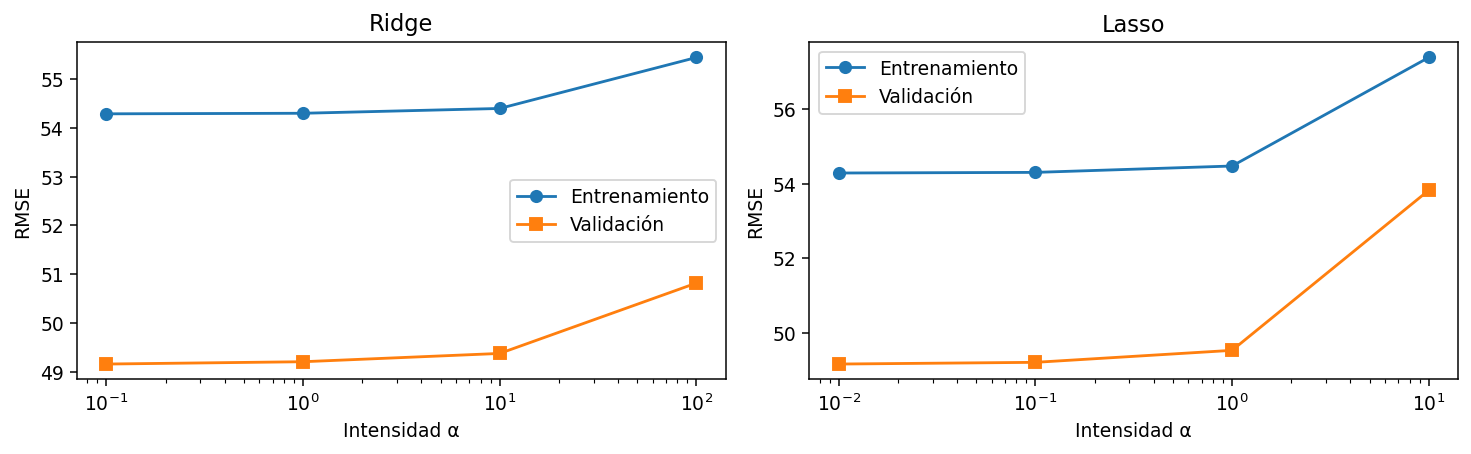

In [11]:
regularization_rows = []
for family in ['Ridge', 'Lasso']:
    for label, model, train_rmse, val_rmse in reg_fits[family]:
        estimator = model.named_steps['modelo']
        coef = estimator.coef_
        regularization_rows.append({
            'Modelo': family, 'α': estimator.alpha, 'Norma L1': np.abs(coef).sum(),
            'Norma L2': np.linalg.norm(coef), 'Máx. |coef.|': np.abs(coef).max(),
            'Coeficientes nulos': int(np.count_nonzero(np.abs(coef) < 1e-8)),
            'RMSE entrenamiento': train_rmse, 'RMSE validación': val_rmse
        })
regularization = pd.DataFrame(regularization_rows).sort_values(['Modelo', 'α']).reset_index(drop=True)
display(regularization.style.format({'α': '{:.2g}', 'Norma L1': '{:.2f}', 'Norma L2': '{:.2f}',
                                     'Máx. |coef.|': '{:.2f}', 'RMSE entrenamiento': '{:.2f}',
                                     'RMSE validación': '{:.2f}'}))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, family in zip(axes, ['Ridge', 'Lasso']):
    subset = regularization[regularization['Modelo'] == family]
    ax.plot(subset['α'], subset['RMSE entrenamiento'], 'o-', label='Entrenamiento')
    ax.plot(subset['α'], subset['RMSE validación'], 's-', label='Validación')
    ax.set(xscale='log', title=family, xlabel='Intensidad α', ylabel='RMSE')
    ax.legend()
plt.tight_layout()
plt.show()

In [12]:
best_reg = reg_test.iloc[0]
best_mae = reg_test.sort_values('MAE', kind='stable').iloc[0]
ridge_low = regularization[(regularization['Modelo'] == 'Ridge')].iloc[0]
ridge_high = regularization[(regularization['Modelo'] == 'Ridge')].iloc[-1]
lasso_low = regularization[(regularization['Modelo'] == 'Lasso')].iloc[0]
lasso_high = regularization[(regularization['Modelo'] == 'Lasso')].iloc[-1]
display(Markdown(f'''### Interpretación de la regresión

1. **Mejor desempeño observado:** {best_reg['Modelo']} obtuvo el menor RMSE de prueba ({best_reg['RMSE']:.2f}); su MAE fue {best_reg['MAE']:.2f} y R² fue {best_reg['R²']:.3f}. El menor MAE corresponde a {best_mae['Modelo']}. Una única partición pequeña no establece superioridad universal.
2. **MAE y RMSE:** MAE promedia magnitudes de error; RMSE eleva al cuadrado antes de promediar y penaliza más los errores grandes. Por ello pueden ordenar modelos de forma distinta.
3. **R² negativo:** significa que el modelo predice peor, en error cuadrático, que la predicción constante igual a la media de `y` en esa partición. R² = 1 indica ajuste perfecto y R² = 0 equivale a esa línea base.
4. **Regularización:** entre α={ridge_low['α']:g} y α={ridge_high['α']:g}, la norma L2 de Ridge pasó de {ridge_low['Norma L2']:.2f} a {ridge_high['Norma L2']:.2f}. En Lasso, entre α={lasso_low['α']:g} y α={lasso_high['α']:g}, los coeficientes nulos pasaron de {int(lasso_low['Coeficientes nulos'])} a {int(lasso_high['Coeficientes nulos'])}. La tabla y curvas muestran cómo cambió el error de entrenamiento y validación: más penalización reduce flexibilidad, pero no garantiza menor error fuera de entrenamiento.
5. **Errores grandes:** pueden relacionarse con variación individual no recogida en las diez variables, ruido de medición, relaciones no capturadas o casos difíciles. Las dos filas por modelo permiten describir el error, pero no identificar su causa exacta.
6. **Causalidad:** un coeficiente predictivo expresa una asociación condicional dentro del modelo y los datos usados. No demuestra que cambiar esa variable cause un cambio en la progresión; harían falta supuestos causales y un diseño apropiado.

**Limitaciones del experimento:** se usó una sola partición, los conjuntos de validación y prueba son pequeños y la búsqueda de hiperparámetros es deliberadamente limitada. Las conclusiones numéricas corresponden a esta semilla y a estos datos.
'''))

### Interpretación de la regresión

1. **Mejor desempeño observado:** MLP obtuvo el menor RMSE de prueba (55.09); su MAE fue 44.86 y R² fue 0.475. El menor MAE corresponde a MLP. Una única partición pequeña no establece superioridad universal.
2. **MAE y RMSE:** MAE promedia magnitudes de error; RMSE eleva al cuadrado antes de promediar y penaliza más los errores grandes. Por ello pueden ordenar modelos de forma distinta.
3. **R² negativo:** significa que el modelo predice peor, en error cuadrático, que la predicción constante igual a la media de `y` en esa partición. R² = 1 indica ajuste perfecto y R² = 0 equivale a esa línea base.
4. **Regularización:** entre α=0.1 y α=100, la norma L2 de Ridge pasó de 56.89 a 31.93. En Lasso, entre α=0.01 y α=10, los coeficientes nulos pasaron de 0 a 6. La tabla y curvas muestran cómo cambió el error de entrenamiento y validación: más penalización reduce flexibilidad, pero no garantiza menor error fuera de entrenamiento.
5. **Errores grandes:** pueden relacionarse con variación individual no recogida en las diez variables, ruido de medición, relaciones no capturadas o casos difíciles. Las dos filas por modelo permiten describir el error, pero no identificar su causa exacta.
6. **Causalidad:** un coeficiente predictivo expresa una asociación condicional dentro del modelo y los datos usados. No demuestra que cambiar esa variable cause un cambio en la progresión; harían falta supuestos causales y un diseño apropiado.

**Limitaciones del experimento:** se usó una sola partición, los conjuntos de validación y prueba son pequeños y la búsqueda de hiperparámetros es deliberadamente limitada. Las conclusiones numéricas corresponden a esta semilla y a estos datos.
